# Pandas - Topic 03 - Select Data in Pandas¶


## Topic Objectives


- Select data in a Pandas DataFrame using multiple approaches: .loc[], .iloc[], .query()


## Import Package for Learning

In [23]:
import numpy as np
import pandas as pd

## Unit 03 - Select Data in Pandas¶

In this unit we will cover

- how to select DataFrame rows and columns with .loc[], .iloc[], .query()


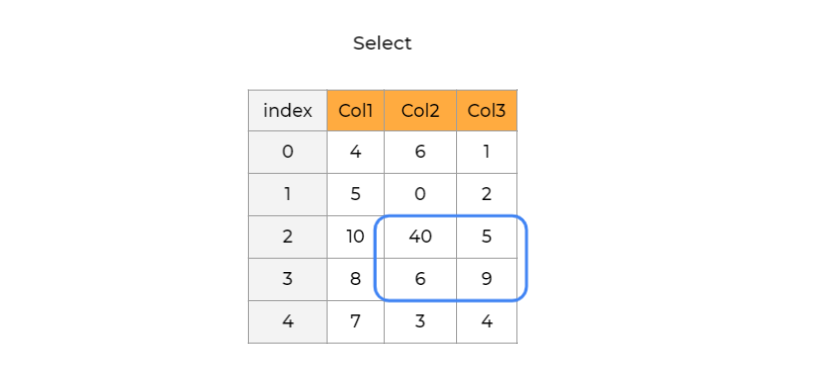

.loc


Let's consider the DataFrame below

In [24]:
np.random.seed(101)
df = pd.DataFrame(data=np.random.randn(5,4),
                  index=['A', 'B', 'C', 'D', 'E'],  
                  columns=['Col1', 'Col2', 'Col3', 'Col4']
                  )
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


You can select rows or rows and columns by label using .loc[]

 - .loc stands for locate


You can select rows using their index label,

1. using a single label returns a series:
  - df.loc['A']
2. Using a slice returns a DataFrame
  - df.loc['A': 'D']
3. Using a list of labels returns a DataFrame:
  - df.loc[['A', 'B']]


The example below grabs the row indexed/labelled as 'A'

In [25]:
df.loc['A']

Col1    2.706850
Col2    0.628133
Col3    0.907969
Col4    0.503826
Name: A, dtype: float64

You will notice it is a Pandas Series and has the content from all columns

In [26]:
type(df.loc['A'])

pandas.core.series.Series

**PRACTICE:** Grab the last row from df using the approach you just learned

Your output should look like

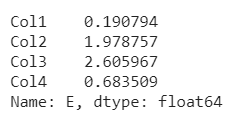

In [27]:
# write your code here
df.loc["E"]

Col1    0.190794
Col2    1.978757
Col3    2.605967
Col4    0.683509
Name: E, dtype: float64

You can grab multiple rows

 - The result is a DataFrame
 - Notice how a list of labels is used

In [28]:
df.loc[['A','D']]

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
D,0.188695,-0.758872,-0.933237,0.955057


You can also combine row labels and column names when selecting your data

1. To grab a single element based on its label and column name
 - df.loc['A', 'Col1']
2. To grab a range by parsing in lists of the row labels and columns name
df.loc[['A','E'],['Col1','Col3']]
3. You can also use slicing:
df.loc['A':'C', 'Col2':'Col4']
4. You can also mix:
df.loc['A':'C', ['Col2']]


*Note:* when slicing using .loc the last value is included (which is not the usual case in Python)


In the example below, we grab an element by parsing its row label and column name

In [29]:
df.loc['A','Col1']

np.float64(2.706849839399938)

**PRACTICE:** Grab the number -0.933237 using .loc[]

First add the required code below to display the Dataframe df

In [30]:
# Run this cell to display the DataFrame
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


In [31]:
# write your code here
df.loc["D","Col3"]

np.float64(-0.9332372163009188)

In the example below, we grab a range by parsing in lists of the row labels and columns name

In [32]:
df.loc[['A','E'],['Col1','Col3']]

,Col1,Col3
A,2.706850,0.907969
E,0.190794,2.605967


**PRACTICE:** Grab the first row, and even columns using .loc[]

Your output should look like a DataFrame, not a Series

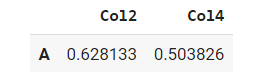

In [33]:
# write your code here
df.loc[["A"], ["Col2","Col4"]]

,Col2,Col4
A,0.628133,0.503826


### iloc¶


Alternatively, you may be interested to subset your data frame based on index location, not on location. You can use .iloc[], which means index location. It accepts the indices of the desired rows and columns. The pandas dataframes have integer indexes for both rows and columns

To select you can:

1. Use a single integer for a single row:
 - df.iloc[0]
2. Use two integers for a value in a row column combination:
 - df.iloc[0, 2]
3. Use a list of integers for rows only:
 - df.iloc[[0,1,2]]
4. Use lists of integers for rows and columns:
 - df.iloc[[0,1,2], [2,3]]
5. Use a slice object on rows:
 - df.iloc[:3]
6 Use a slice object on rows and columns:
 - df.iloc[:2, 3:]

The example below grabs the row at index 0.

In this case, you don't have to know/remember the index label from the row at index 0 is "A"

In [34]:
df.iloc[0]

Col1    2.706850
Col2    0.628133
Col3    0.907969
Col4    0.503826
Name: A, dtype: float64

You can subset ranges using notation similar to NumPy

- The example below gets rows until index 2 (not including index 3) and columns until index 3 (not including index 4)
  - Remember that "A" is row index 0 and "Col1" is column index 0

In [35]:
df.iloc[:3,:4]

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001


**PRACTICE:** Using .iloc[], grab the last column and last 3 rows

 - You may use the regular slicing or the negative slicing approach that you learned in the NumPy lesson; it is up to you

Your output should look like

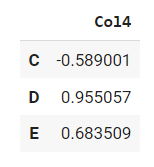

In [36]:
# write your code here
df.iloc[2:,3:4]

,Col4
C,-0.589001
D,0.955057
E,0.683509


In [37]:
df.iloc[2:,3]

C   -0.589001
D    0.955057
E    0.683509
Name: Col4, dtype: float64

In [38]:
df.loc[["C","D","E"], ["Col4"]]

,Col4
C,-0.589001
D,0.955057
E,0.683509


.query()¶

Query the columns of a DataFrame with a boolean expression.

 - Quick recap of df first

In [39]:
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


You can select data in your DataFrame using notation similar to NumPy

 - The example below creates a boolean series on Col4 > 0and is parsed at df

   - You will notice that row "C" is not selected since the value in row C at Col4 was negative
   - Think of it like: I want the values from Col4 that are greater than 0

In [40]:
df[df['Col4']>0]

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


There is an alternative pythonic way to subset data using .query()

 - You parse as a string the operation you are interested in

In [41]:
df.query("Col4 > 0")

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


You can combine multiple operations.

 - The example below considers data where Col4 > 0 and Col1 > 0.5
 - If you want to use an or operation, just write or

In [42]:
df.query("Col4 > 0 and Col1 > 0.5 ")

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965


Let's recap df

In [43]:
df

,Col1,Col2,Col3,Col4
A,2.706850,0.628133,0.907969,0.503826
B,0.651118,-0.319318,-0.848077,0.605965
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509


 - Note the difference between the outputs below
First case

In [44]:
df.query('Col2 > 0.8 or Col2 < 0 and Col1 > 0.5')

,Col1,Col2,Col3,Col4
B,0.651118,-0.319318,-0.848077,0.605965
E,0.190794,1.978757,2.605967,0.683509


Second case

In [45]:
df.query('(Col2 > 0.8 or Col2 < 0) and Col1 > 0.5')

,Col1,Col2,Col3,Col4
B,0.651118,-0.319318,-0.848077,0.605965


Why did that happen?

- The parentheses, in combination with the operators (or and and) gave priority when selecting the orders to execute the query command
  - The first case: first it queried Col2 < 0 and Col1 > 0.5, then Col2 > 0.8
  - The second case: first it queried Col2 > 0.8 or Col2 < 0, then the result was queried with and Col1 > 0.5


**PRACTICE:** Select values where Col3 is greater than 0.4 or Col4 is greater than 0.7. Then the result should be queried with Col1 smaller than 0.2

Your output should look like

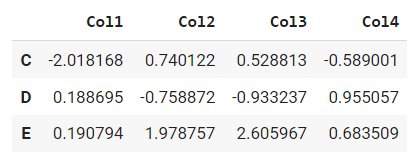

In [46]:
# write your code here

df.query("(Col3 > 0.4 or Col4 > 0.7) and Col1 < 0.2")

,Col1,Col2,Col3,Col4
C,-2.018168,0.740122,0.528813,-0.589001
D,0.188695,-0.758872,-0.933237,0.955057
E,0.190794,1.978757,2.605967,0.683509
